In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OrdinalEncoder,OneHotEncoder,LabelEncoder
from imblearn.over_sampling import SMOTE

In [ ]:
file_path="/content/drive/MyDrive/AI_ ML_Class_Works/dataset/adult_dataset.csv"
df_adult=pd.read_csv(file_path)
df_adult.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K


In [ ]:
df_adult.shape

(48842, 15)

In [ ]:
df_adult.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,46400.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,46400.000000
mean,38.679116,1.896641e+05,10.078089,1079.067626,87.502314,40.448599
std,13.952954,1.056040e+05,2.570973,7452.019058,403.004552,12.646992
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,255.000000,1.490400e+06,16.000000,99999.000000,4356.000000,250.000000


In [ ]:
df_adult.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             46400 non-null  float64
 1   workclass       45480 non-null  object 
 2   fnlwgt          48842 non-null  int64  
 3   education       48842 non-null  object 
 4   education-num   48842 non-null  int64  
 5   marital-status  48842 non-null  object 
 6   occupation      45485 non-null  object 
 7   relationship    48842 non-null  object 
 8   race            48842 non-null  object 
 9   sex             48842 non-null  object 
 10  capital-gain    48842 non-null  int64  
 11  capital-loss    48842 non-null  int64  
 12  hours-per-week  46400 non-null  float64
 13  native-country  46137 non-null  object 
 14  income          48842 non-null  object 
dtypes: float64(2), int64(4), object(9)
memory usage: 5.6+ MB


In [ ]:
df_adult.dtypes


,0
age,float64
workclass,object
fnlwgt,int64
education,object
education-num,int64
marital-status,object
occupation,object
relationship,object
race,object
sex,object


In [ ]:
df_adult.isna().mean()*100

,0
age,4.999795
workclass,6.883420
fnlwgt,0.000000
education,0.000000
education-num,0.000000
marital-status,0.000000
occupation,6.873183
relationship,0.000000
race,0.000000
sex,0.000000


In [ ]:
df_adult.duplicated().sum()


np.int64(16)

In [ ]:
print(df_adult.duplicated().sum())

df_adult = df_adult.drop_duplicates()


16


In [ ]:
print(df_adult.duplicated().sum())

0


In [ ]:
pd.set_option("display.max_columns",None)
print(df_adult["age"].unique())
print(df_adult["workclass"].unique())
print(df_adult["occupation"].unique())
print(df_adult["native-country"].unique())

#print(df_adult["hours-per-week"].unique())

[ 39.  50.  38.  53.  28.  37.  49.  52.  31.  42.  30.  23.  32.  40.
  34.  25.  nan  54.  35.  43.  59.  56.  19.  20.  45.  22.  48.  21.
  24.  57.  44.  41.  29.  18.  47.  46.  79.  27.  67.  33.  76.  17.
 120.  36.  55.  61.  70.  64.  71.  68.  66.  51.  58.  26.  60.  90.
  75.  65.  77.  62.  63.  80.  74.  72.  69.  73.  81.  88. 250.  78.
  82.  83. 255.  84.  85. 225. 230.  86.  87.  89. 140. 100. 210.]
['State-gov' 'Self-emp-not-inc' 'Private' 'Federal-gov' nan 'Local-gov'
 '?' 'Self-emp-inc' 'Without-pay' 'Never-worked']
['Adm-clerical' 'Exec-managerial' 'Handlers-cleaners' 'Prof-specialty'
 'Other-service' 'Sales' 'Craft-repair' 'Transport-moving'
 'Farming-fishing' 'Machine-op-inspct' 'Tech-support' nan
 'Protective-serv' '?' 'Armed-Forces' 'Priv-house-serv']
[nan 'United-States' 'Cuba' 'Jamaica' 'India' '?' 'Mexico' 'South'
 'Puerto-Rico' 'Honduras' 'England' 'Germany' 'Iran' 'Philippines' 'Italy'
 'Columbia' 'Cambodia' 'Thailand' 'Canada' 'Ecuador' 'Laos' 'Taiwan'


In [ ]:
df_adult["age"].unique()

array([ 39.,  50.,  38.,  53.,  28.,  37.,  49.,  52.,  31.,  42.,  30.,
        23.,  32.,  40.,  34.,  25.,  nan,  54.,  35.,  43.,  59.,  56.,
        19.,  20.,  45.,  22.,  48.,  21.,  24.,  57.,  44.,  41.,  29.,
        18.,  47.,  46.,  79.,  27.,  67.,  33.,  76.,  17., 120.,  36.,
        55.,  61.,  70.,  64.,  71.,  68.,  66.,  51.,  58.,  26.,  60.,
        90.,  75.,  65.,  77.,  62.,  63.,  80.,  74.,  72.,  69.,  73.,
        81.,  88., 250.,  78.,  82.,  83., 255.,  84.,  85., 225., 230.,
        86.,  87.,  89., 140., 100., 210.])

clean the age datset. handle inconsistent data.

In [ ]:

df_adult["age"].loc[(df_adult["age"]<18)| (df_adult["age"]>100)]=np.nan

/tmp/ipykernel_55096/126213067.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  df_adult["age"].loc[(df_adult["age"]<18)| (df_adult["age"]>100)]=np.nan


In [ ]:
df_adult["age"].unique()

array([ 39.,  50.,  38.,  53.,  28.,  37.,  49.,  52.,  31.,  42.,  30.,
        23.,  32.,  40.,  34.,  25.,  nan,  54.,  35.,  43.,  59.,  56.,
        19.,  20.,  45.,  22.,  48.,  21.,  24.,  57.,  44.,  41.,  29.,
        18.,  47.,  46.,  79.,  27.,  67.,  33.,  76.,  36.,  55.,  61.,
        70.,  64.,  71.,  68.,  66.,  51.,  58.,  26.,  60.,  90.,  75.,
        65.,  77.,  62.,  63.,  80.,  74.,  72.,  69.,  73.,  81.,  88.,
        78.,  82.,  83.,  84.,  85.,  86.,  87.,  89., 100.])

In [ ]:
df_adult["workclass"].unique()

array(['State-gov', 'Self-emp-not-inc', 'Private', 'Federal-gov', nan,
       'Local-gov', '?', 'Self-emp-inc', 'Without-pay', 'Never-worked'],
      dtype=object)

In [ ]:
df_adult["workclass"]=df_adult["workclass"].str.strip().str.title().str.capitalize()

In [ ]:

df_adult["workclass"]=df_adult["workclass"].replace('?',np.nan)

In [ ]:
df_adult["workclass"].unique()

array(['State-gov', 'Self-emp-not-inc', 'Private', 'Federal-gov', nan,
       'Local-gov', 'Self-emp-inc', 'Without-pay', 'Never-worked'],
      dtype=object)

In [ ]:
df_adult.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'sex',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'income'],
      dtype='object')

In [ ]:
df_adult["education"].unique()
df_adult["education"]=df_adult["education"].str.strip().str.title().str.capitalize()

In [ ]:
df_adult["education"].unique()

array(['Bachelors', 'Hs-grad', '11th', 'Masters', '9th', 'Some-college',
       'Assoc-acdm', 'Assoc-voc', '7th-8th', 'Doctorate', 'Prof-school',
       '5th-6th', '10th', '1st-4th', 'Preschool', '12th'], dtype=object)

In [ ]:
df_adult["marital-status"].unique()


array(['Never-married', 'Married-civ-spouse', 'Divorced',
       'Married-spouse-absent', 'Separated', 'Married-AF-spouse',
       'Widowed'], dtype=object)

In [ ]:
df_adult["marital-status"]=df_adult["marital-status"].str.strip().str.title().str.capitalize()

In [ ]:
df_adult["marital-status"].unique()

array(['Never-married', 'Married-civ-spouse', 'Divorced',
       'Married-spouse-absent', 'Separated', 'Married-af-spouse',
       'Widowed'], dtype=object)

In [ ]:
df_adult["occupation"].unique()

array(['Adm-clerical', 'Exec-managerial', 'Handlers-cleaners',
       'Prof-specialty', 'Other-service', 'Sales', 'Craft-repair',
       'Transport-moving', 'Farming-fishing', 'Machine-op-inspct',
       'Tech-support', nan, 'Protective-serv', '?', 'Armed-Forces',
       'Priv-house-serv'], dtype=object)

In [ ]:
df_adult["occupation"]=df_adult["occupation"].replace('?',np.nan)

In [ ]:
df_adult["education"]=df_adult["education"].str.strip().str.title().str.capitalize()

In [ ]:
df_adult["occupation"].unique()

array(['Adm-clerical', 'Exec-managerial', 'Handlers-cleaners',
       'Prof-specialty', 'Other-service', 'Sales', 'Craft-repair',
       'Transport-moving', 'Farming-fishing', 'Machine-op-inspct',
       'Tech-support', nan, 'Protective-serv', 'Armed-Forces',
       'Priv-house-serv'], dtype=object)

In [ ]:
df_adult["relationship"].unique()

array(['Not-in-family', 'Husband', 'Wife', 'Own-child', 'Unmarried',
       'Other-relative'], dtype=object)

In [ ]:
df_adult["relationship"]=df_adult["relationship"].str.strip().str.title().str.capitalize()
df_adult["relationship"].unique()

array(['Not-in-family', 'Husband', 'Wife', 'Own-child', 'Unmarried',
       'Other-relative'], dtype=object)

In [ ]:
df_adult.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'sex',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'income'],
      dtype='object')

In [ ]:
df_adult["race"].unique()



array(['White', 'Black', 'Asian-Pac-Islander', 'Amer-Indian-Eskimo',
       'Other'], dtype=object)

In [ ]:
df_adult["race"]=df_adult["race"].str.strip().str.title().str.capitalize()
df_adult["race"].unique()



array(['White', 'Black', 'Asian-pac-islander', 'Amer-indian-eskimo',
       'Other'], dtype=object)

In [ ]:
df_adult["sex"].unique()



array(['Male', 'Female'], dtype=object)

In [ ]:
df_adult["sex"]=df_adult["sex"].str.strip().str.title().str.capitalize()
df_adult["sex"].unique()


array(['Male', 'Female'], dtype=object)

In [ ]:
df_adult["native-country"].unique()



array([nan, 'United-States', 'Cuba', 'Jamaica', 'India', '?', 'Mexico',
       'South', 'Puerto-Rico', 'Honduras', 'England', 'Germany', 'Iran',
       'Philippines', 'Italy', 'Columbia', 'Cambodia', 'Thailand',
       'Canada', 'Ecuador', 'Laos', 'Taiwan', 'Haiti', 'Portugal',
       'Dominican-Republic', 'El-Salvador', 'Poland', 'France',
       'Guatemala', 'China', 'Japan', 'Yugoslavia', 'Peru',
       'Outlying-US(Guam-USVI-etc)', 'Scotland', 'Trinadad&Tobago',
       'Greece', 'Nicaragua', 'Vietnam', 'Hong', 'Ireland', 'Hungary',
       'Holand-Netherlands'], dtype=object)

In [ ]:
df_adult["native-country"]=df_adult["native-country"].str.strip().str.title().str.capitalize()
df_adult["native-country"]=df_adult["native-country"].replace('?',np.nan)
df_adult["native-country"].unique()

array([nan, 'United-states', 'Cuba', 'Jamaica', 'India', 'Mexico',
       'South', 'Puerto-rico', 'Honduras', 'England', 'Germany', 'Iran',
       'Philippines', 'Italy', 'Columbia', 'Cambodia', 'Thailand',
       'Canada', 'Ecuador', 'Laos', 'Taiwan', 'Haiti', 'Portugal',
       'Dominican-republic', 'El-salvador', 'Poland', 'France',
       'Guatemala', 'China', 'Japan', 'Yugoslavia', 'Peru',
       'Outlying-us(guam-usvi-etc)', 'Scotland', 'Trinadad&tobago',
       'Greece', 'Nicaragua', 'Vietnam', 'Hong', 'Ireland', 'Hungary',
       'Holand-netherlands'], dtype=object)

#Divide into train test split so taken income as target value

In [ ]:
df_adult.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'sex',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'income'],
      dtype='object')

In [ ]:
df_adult["income"].unique()

array(['<=50K', '>50K', '<=50K.', '>50K.'], dtype=object)

In [ ]:
df_adult["income"]=df_adult["income"].str.rstrip(". ")

In [ ]:
df_adult["income"].unique()

array(['<=50K', '>50K'], dtype=object)

In [ ]:
X=df_adult.drop(columns="income",axis=1)
y=df_adult["income"]

Check class imbalance

In [ ]:
y.value_counts() #• Total Samples: 48,842
# Majority Class (<=50K): 37,155 rows (76.07%)
#Minority Class (>50K): 11,687 rows (23.93%) class is imbalanced


,count
income,
<=50K,37139
>50K,11687


In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

#Divide into numerical and categorical columns

In [ ]:
num_cols=X_train.select_dtypes(include=["number"]).columns
cat_cols=X_train.select_dtypes(include=["object"]).columns

In [ ]:
num_cols

Index(['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss',
       'hours-per-week'],
      dtype='object')

In [ ]:
cat_cols

Index(['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'sex', 'native-country'],
      dtype='object')

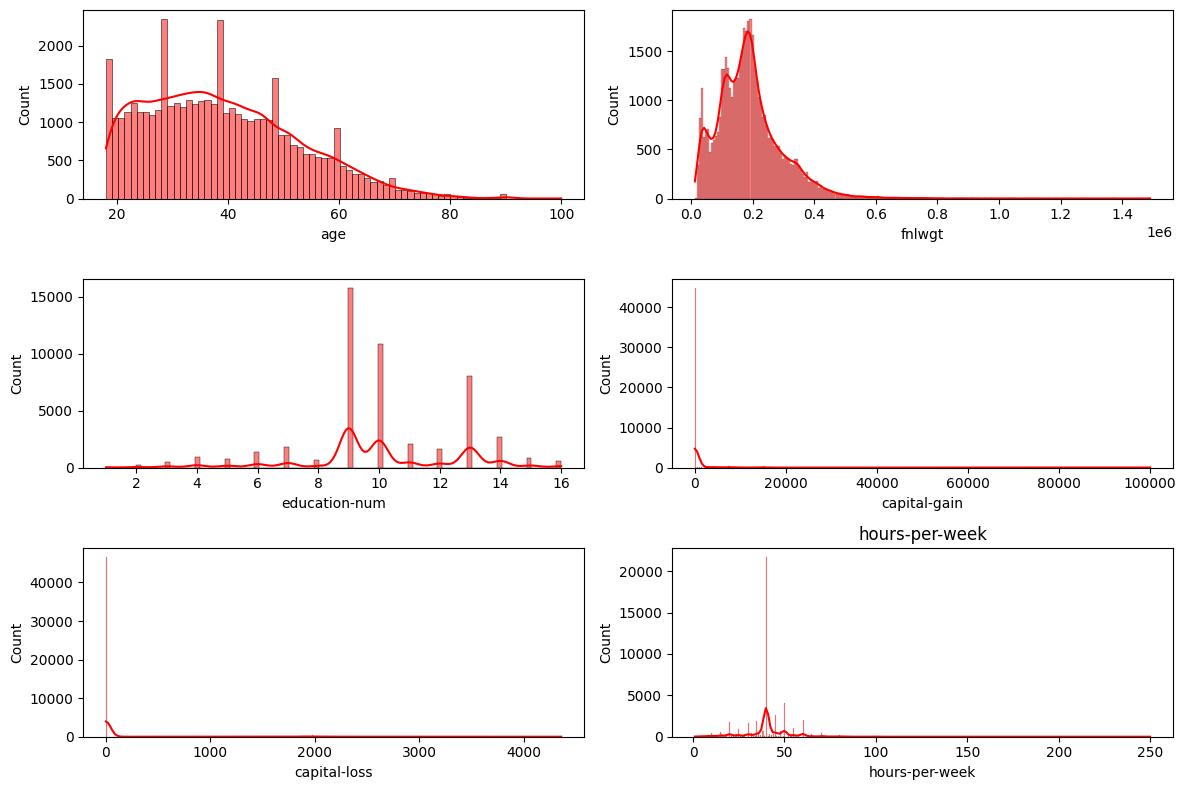

In [ ]:
#Hisplot
plt.figure(figsize=(12,8))
for i,col in enumerate(num_cols,1):
  plt.subplot(3,2,i)
  sns.histplot(data=df_adult[col],kde=True,color="red")
plt.title(col)
plt.tight_layout()
plt.show()

#Handle numerical values:


In [ ]:
num_imputer=SimpleImputer(strategy="median")
X_train_num=num_imputer.fit_transform(X_train[num_cols])
X_test_num=num_imputer.transform(X_test[num_cols])

In [ ]:
scaler=StandardScaler()
X_train_num_scale=scaler.fit_transform(X_train_num)
X_test_num_scale=scaler.transform(X_test_num)

In [ ]:
#convert into dataframe
X_train_num_scale_df=pd.DataFrame(X_train_num_scale,columns=num_cols)
X_test_num_scale_df=pd.DataFrame(X_test_num_scale,columns=num_cols)

#Handle Categorical values

In [ ]:
cat_cols

Index(['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'sex', 'native-country'],
      dtype='object')

In [ ]:
cat_imputer=SimpleImputer(strategy="most_frequent")
X_train_cat=cat_imputer.fit_transform(X_train[cat_cols])
X_test_cat=cat_imputer.transform(X_test[cat_cols])

In [ ]:
#Convert it into a datframe before encoding
X_train_cat_df=pd.DataFrame(X_train_cat,columns=cat_cols)
X_test_cat_df=pd.DataFrame(X_test_cat,columns=cat_cols)
for col in cat_cols:
  print(f"{col} ----> {X_train_cat_df[col].unique()}")

workclass ----> ['Private' 'Self-emp-not-inc' 'Local-gov' 'Self-emp-inc' 'State-gov'
 'Federal-gov' 'Without-pay' 'Never-worked']
education ----> ['Assoc-voc' '9th' 'Bachelors' 'Hs-grad' 'Some-college' '11th' 'Masters'
 'Prof-school' 'Assoc-acdm' '7th-8th' '10th' 'Preschool' '12th'
 'Doctorate' '5th-6th' '1st-4th']
marital-status ----> ['Divorced' 'Married-civ-spouse' 'Separated' 'Never-married'
 'Married-spouse-absent' 'Widowed' 'Married-af-spouse']
occupation ----> ['Prof-specialty' 'Craft-repair' 'Adm-clerical' 'Other-service'
 'Machine-op-inspct' 'Farming-fishing' 'Sales' 'Exec-managerial'
 'Handlers-cleaners' 'Protective-serv' 'Transport-moving' 'Tech-support'
 'Priv-house-serv' 'Armed-Forces']
relationship ----> ['Unmarried' 'Husband' 'Not-in-family' 'Own-child' 'Wife' 'Other-relative']
race ----> ['White' 'Other' 'Amer-indian-eskimo' 'Black' 'Asian-pac-islander']
sex ----> ['Female' 'Male']
native-country ----> ['United-states' 'Guatemala' 'Haiti' 'Japan' 'Germany' 'Cuba' 'Peru'

In [ ]:
#Education has an order all other columns are nominal
ordinal_cols=[]
ordinal_list=["education"]
nominal_cols=[]
for col in cat_cols:
  if col in ordinal_list:
    ordinal_cols.append(col)
  else:
    nominal_cols.append(col)
print("Ordinal columns:",ordinal_cols)
print("Nominal columns:",nominal_cols)


Ordinal columns: ['education']
Nominal columns: ['workclass', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


In [ ]:
ordinal_categories=['Preschool','1st-4th','5th-6th','7th-8th','9th', '10th','11th','12th','Hs-grad', 'Some-college', 'Assoc-voc',
                    'Assoc-acdm', 'Bachelors','Masters', 'Prof-school', 'Doctorate']

encoder_ord=OrdinalEncoder(categories=[ordinal_categories],dtype=int)
X_train_ord = encoder_ord.fit_transform(X_train_cat_df[ordinal_cols])
X_test_ord  = encoder_ord.transform(X_test_cat_df[ordinal_cols])

X_train_ord_df=pd.DataFrame(X_train_ord,columns=ordinal_cols,index=X_train_cat_df.index)
X_test_ord_df=pd.DataFrame(X_test_ord,columns=ordinal_cols,index=X_test_cat_df.index)


In [ ]:
X_train_ord_df.head()

,education
0,10
1,4
2,12
3,8
4,8


In [ ]:
encoder_hot=OneHotEncoder(handle_unknown="ignore",sparse_output=False,dtype=int)
X_train_onehot_df=pd.DataFrame(
    encoder_hot.fit_transform(X_train_cat_df[nominal_cols]),
    columns=encoder_hot.get_feature_names_out(nominal_cols),
    index=X_train_cat_df.index)
X_test_onehot_df=pd.DataFrame(
    encoder_hot.transform(X_train_cat_df[nominal_cols]),
    columns=encoder_hot.get_feature_names_out(nominal_cols),
    index=X_train_cat_df.index)
display(X_train_onehot_df.head())


,workclass_Federal-gov,workclass_Local-gov,workclass_Never-worked,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,workclass_Without-pay,marital-status_Divorced,marital-status_Married-af-spouse,marital-status_Married-civ-spouse,marital-status_Married-spouse-absent,marital-status_Never-married,marital-status_Separated,marital-status_Widowed,occupation_Adm-clerical,occupation_Armed-Forces,occupation_Craft-repair,occupation_Exec-managerial,occupation_Farming-fishing,occupation_Handlers-cleaners,occupation_Machine-op-inspct,occupation_Other-service,occupation_Priv-house-serv,occupation_Prof-specialty,occupation_Protective-serv,occupation_Sales,occupation_Tech-support,occupation_Transport-moving,relationship_Husband,relationship_Not-in-family,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,relationship_Wife,race_Amer-indian-eskimo,race_Asian-pac-islander,race_Black,race_Other,race_White,sex_Female,sex_Male,native-country_Cambodia,native-country_Canada,native-country_China,native-country_Columbia,native-country_Cuba,native-country_Dominican-republic,native-country_Ecuador,native-country_El-salvador,native-country_England,native-country_France,native-country_Germany,native-country_Greece,native-country_Guatemala,native-country_Haiti,native-country_Holand-netherlands,native-country_Honduras,native-country_Hong,native-country_Hungary,native-country_India,native-country_Iran,native-country_Ireland,native-country_Italy,native-country_Jamaica,native-country_Japan,native-country_Laos,native-country_Mexico,native-country_Nicaragua,native-country_Outlying-us(guam-usvi-etc),native-country_Peru,native-country_Philippines,native-country_Poland,native-country_Portugal,native-country_Puerto-rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&tobago,native-country_United-states,native-country_Vietnam,native-country_Yugoslavia
0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
1,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
3,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
4,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0


In [ ]:
#Concating two numerical columns
X_train_cat_enc=pd.concat([X_train_ord_df,X_train_onehot_df],axis=1)
X_test_cat_enc=pd.concat([X_test_ord_df,X_train_onehot_df],axis=1)
X_train_cat_enc.head()

,education,workclass_Federal-gov,workclass_Local-gov,workclass_Never-worked,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,workclass_Without-pay,marital-status_Divorced,marital-status_Married-af-spouse,marital-status_Married-civ-spouse,marital-status_Married-spouse-absent,marital-status_Never-married,marital-status_Separated,marital-status_Widowed,occupation_Adm-clerical,occupation_Armed-Forces,occupation_Craft-repair,occupation_Exec-managerial,occupation_Farming-fishing,occupation_Handlers-cleaners,occupation_Machine-op-inspct,occupation_Other-service,occupation_Priv-house-serv,occupation_Prof-specialty,occupation_Protective-serv,occupation_Sales,occupation_Tech-support,occupation_Transport-moving,relationship_Husband,relationship_Not-in-family,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,relationship_Wife,race_Amer-indian-eskimo,race_Asian-pac-islander,race_Black,race_Other,race_White,sex_Female,sex_Male,native-country_Cambodia,native-country_Canada,native-country_China,native-country_Columbia,native-country_Cuba,native-country_Dominican-republic,native-country_Ecuador,native-country_El-salvador,native-country_England,native-country_France,native-country_Germany,native-country_Greece,native-country_Guatemala,native-country_Haiti,native-country_Holand-netherlands,native-country_Honduras,native-country_Hong,native-country_Hungary,native-country_India,native-country_Iran,native-country_Ireland,native-country_Italy,native-country_Jamaica,native-country_Japan,native-country_Laos,native-country_Mexico,native-country_Nicaragua,native-country_Outlying-us(guam-usvi-etc),native-country_Peru,native-country_Philippines,native-country_Poland,native-country_Portugal,native-country_Puerto-rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&tobago,native-country_United-states,native-country_Vietnam,native-country_Yugoslavia
0,10,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
1,4,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,12,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
3,8,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
4,8,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0


In [ ]:
#concating numerical and categorical columns
X_train_final=pd.concat([X_train_num_scale_df,X_train_cat_enc],axis=1)
X_test_final=pd.concat([X_test_num_scale_df,X_train_cat_enc],axis=1)
display(X_train_final.head())

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week,education,workclass_Federal-gov,workclass_Local-gov,workclass_Never-worked,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,workclass_Without-pay,marital-status_Divorced,marital-status_Married-af-spouse,marital-status_Married-civ-spouse,marital-status_Married-spouse-absent,marital-status_Never-married,marital-status_Separated,marital-status_Widowed,occupation_Adm-clerical,occupation_Armed-Forces,occupation_Craft-repair,occupation_Exec-managerial,occupation_Farming-fishing,occupation_Handlers-cleaners,occupation_Machine-op-inspct,occupation_Other-service,occupation_Priv-house-serv,occupation_Prof-specialty,occupation_Protective-serv,occupation_Sales,occupation_Tech-support,occupation_Transport-moving,relationship_Husband,relationship_Not-in-family,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,relationship_Wife,race_Amer-indian-eskimo,race_Asian-pac-islander,race_Black,race_Other,race_White,sex_Female,sex_Male,native-country_Cambodia,native-country_Canada,native-country_China,native-country_Columbia,native-country_Cuba,native-country_Dominican-republic,native-country_Ecuador,native-country_El-salvador,native-country_England,native-country_France,native-country_Germany,native-country_Greece,native-country_Guatemala,native-country_Haiti,native-country_Holand-netherlands,native-country_Honduras,native-country_Hong,native-country_Hungary,native-country_India,native-country_Iran,native-country_Ireland,native-country_Italy,native-country_Jamaica,native-country_Japan,native-country_Laos,native-country_Mexico,native-country_Nicaragua,native-country_Outlying-us(guam-usvi-etc),native-country_Peru,native-country_Philippines,native-country_Poland,native-country_Portugal,native-country_Puerto-rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&tobago,native-country_United-states,native-country_Vietnam,native-country_Yugoslavia
0,0.163937,-0.992522,0.356973,0.388864,-0.216273,-0.036504,10,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
1,-0.367301,0.170047,-1.970414,-0.144058,-0.216273,-0.036504,4,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,-0.443192,0.030238,1.132769,-0.144058,-0.216273,0.125598,12,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
3,0.391611,-0.172788,-0.418822,-0.144058,-0.216273,-0.117556,8,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
4,-1.126212,0.684139,-0.418822,-0.144058,-0.216273,-0.036504,8,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0


In [ ]:
print("Train:",X_train_final.shape,"Test:",X_test_final.shape)


Train: (39060, 90) Test: (39060, 90)


#Label Encoding for target column


In [ ]:
y_train.unique()

array(['<=50K', '>50K'], dtype=object)

In [ ]:
encoder_lb=LabelEncoder()
y_train_enc=encoder_lb.fit_transform(y_train)
y_test_enc=encoder_lb.transform(y_test)
print(encoder_lb.classes_)
print(pd.Series(y_train_enc).value_counts())

['<=50K' '>50K']
0    29711
1     9349
Name: count, dtype: int64


#Class Imbalance handling

In [ ]:
smote=SMOTE(random_state=42)
X_train_bal,y_train_bal=smote.fit_resample(X_train_final,y_train_enc)

print("Before SMOTE:", pd.DataFrame(y_train_enc).value_counts().to_dict())
print("After  SMOTE:", pd.DataFrame(y_train_bal).value_counts().to_dict())
print("Balanced train shape:", X_train_bal.shape)

Before SMOTE: {(0,): 29711, (1,): 9349}
After  SMOTE: {(0,): 29711, (1,): 29711}
Balanced train shape: (59422, 90)


Feature Selection -- coorelation matrix

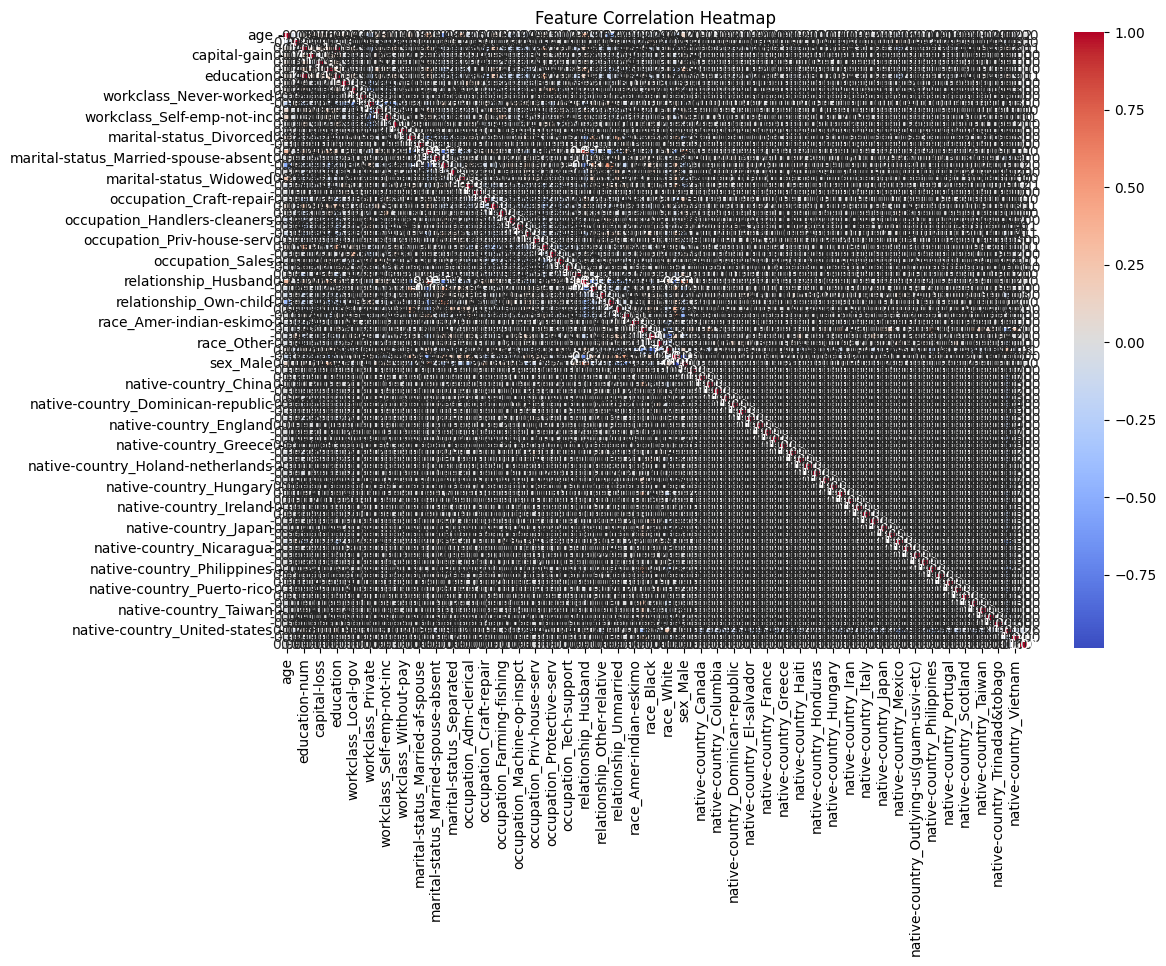

In [ ]:
corr=X_train_bal.corr()
plt.figure(figsize=(12,8))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidth=0.5
)


plt.title("Feature Correlation Heatmap")
plt.show()

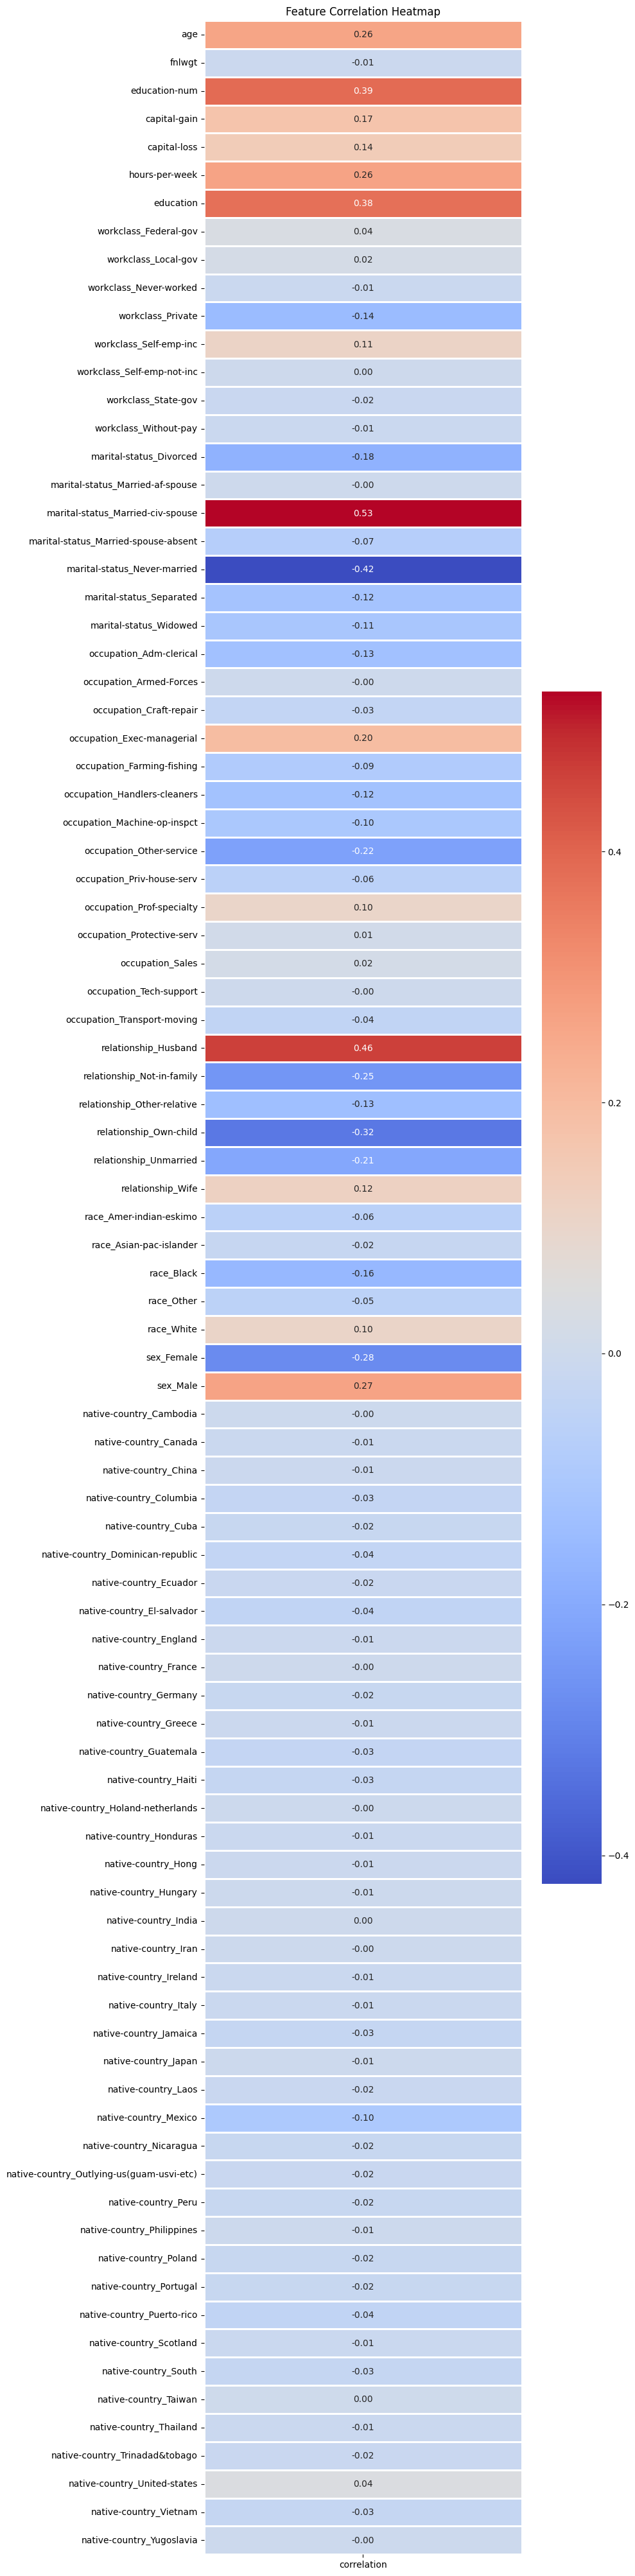

In [ ]:
corr_target=X_train_bal.corrwith(pd.DataFrame(y_train_bal).iloc[:,0]).to_frame(name="correlation")
plt.figure(figsize=(10, 40), dpi=100)
sns.heatmap(
    corr_target,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidth=1
)

plt.tight_layout()
plt.title("Feature Correlation Heatmap")
plt.show()

In [ ]:
X_train_bal.columns

Index(['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss',
       'hours-per-week', 'education', 'workclass_Federal-gov',
       'workclass_Local-gov', 'workclass_Never-worked', 'workclass_Private',
       'workclass_Self-emp-inc', 'workclass_Self-emp-not-inc',
       'workclass_State-gov', 'workclass_Without-pay',
       'marital-status_Divorced', 'marital-status_Married-af-spouse',
       'marital-status_Married-civ-spouse',
       'marital-status_Married-spouse-absent', 'marital-status_Never-married',
       'marital-status_Separated', 'marital-status_Widowed',
       'occupation_Adm-clerical', 'occupation_Armed-Forces',
       'occupation_Craft-repair', 'occupation_Exec-managerial',
       'occupation_Farming-fishing', 'occupation_Handlers-cleaners',
       'occupation_Machine-op-inspct', 'occupation_Other-service',
       'occupation_Priv-house-serv', 'occupation_Prof-specialty',
       'occupation_Protective-serv', 'occupation_Sales',
       'occupation_Tech-support

In [ ]:
features_selected=["education-num","relationship_Husband","marital-status_Married-civ-spouse"]
X_train_selected=X_train_bal[features_selected]
X_test_selected=X_train_final[features_selected] #threshold between 0.3 and 0.8 columns

EDA  __ Visualization


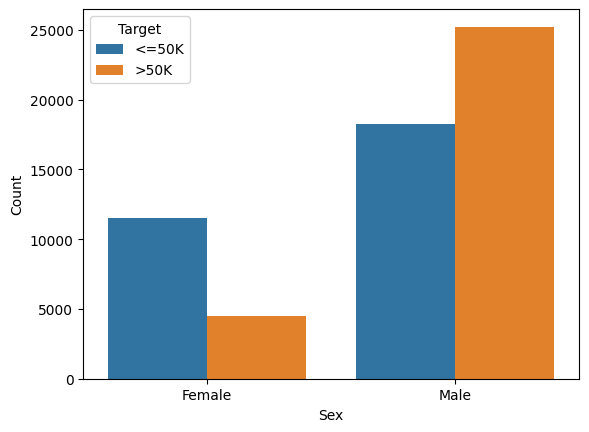

In [83]:
# Compare target with sex
sns.countplot(
    x=X_train_bal[["sex_Female", "sex_Male"]].idxmax(axis=1).str.replace("sex_", ""),
    hue=pd.Series(y_train_bal).map({1: ">50K", 0: "<=50K"}),
)
plt.xlabel("Sex")
plt.ylabel("Count")
plt.legend(title="Target")
plt.show()

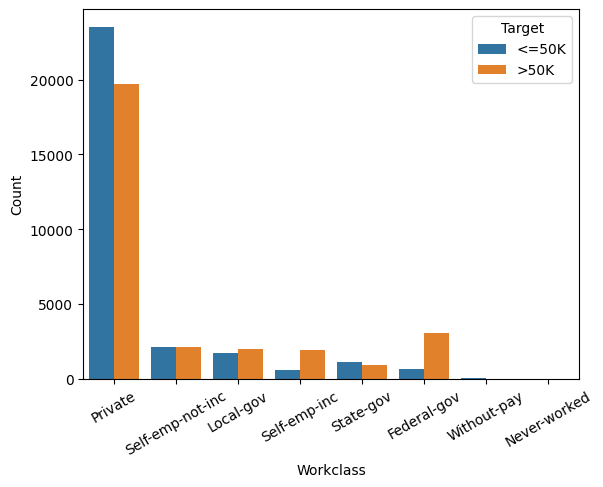

In [84]:
# Compare target with workclass
workclass_cols = [
    "workclass_Federal-gov",
    "workclass_Local-gov",
    "workclass_Never-worked",
    "workclass_Private",
    "workclass_Self-emp-inc",
    "workclass_Self-emp-not-inc",
    "workclass_State-gov",
    "workclass_Without-pay",
]
sns.countplot(
    x=X_train_bal[workclass_cols].idxmax(axis=1).str.replace("workclass_", ""),
    hue=pd.Series(y_train_bal).map({1: ">50K", 0: "<=50K"}),
)
plt.xticks(rotation=30)
plt.xlabel("Workclass")
plt.ylabel("Count")
plt.legend(title="Target")
plt.show()

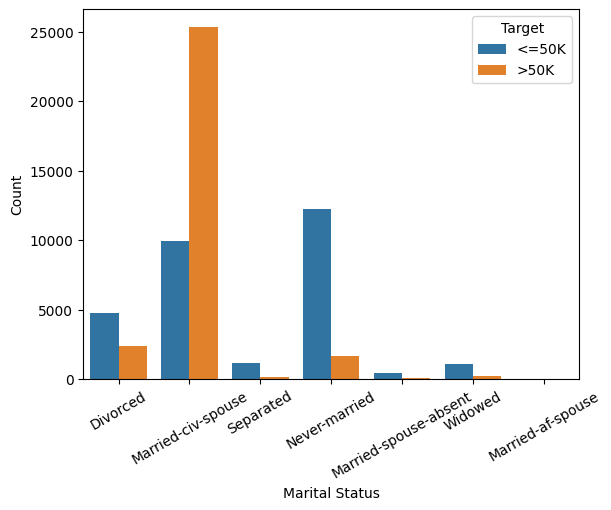

In [85]:
# Compare target with marital-status
marital_cols = [
    "marital-status_Divorced",
    "marital-status_Married-af-spouse",
    "marital-status_Married-civ-spouse",
    "marital-status_Married-spouse-absent",
    "marital-status_Never-married",
    "marital-status_Separated",
    "marital-status_Widowed",
]
sns.countplot(
    x=X_train_bal[marital_cols].idxmax(axis=1).str.replace("marital-status_", ""),
    hue=pd.Series(y_train_bal).map({1: ">50K", 0: "<=50K"}),
)
plt.xticks(rotation=30)
plt.xlabel("Marital Status")
plt.ylabel("Count")
plt.legend(title="Target")
plt.show()

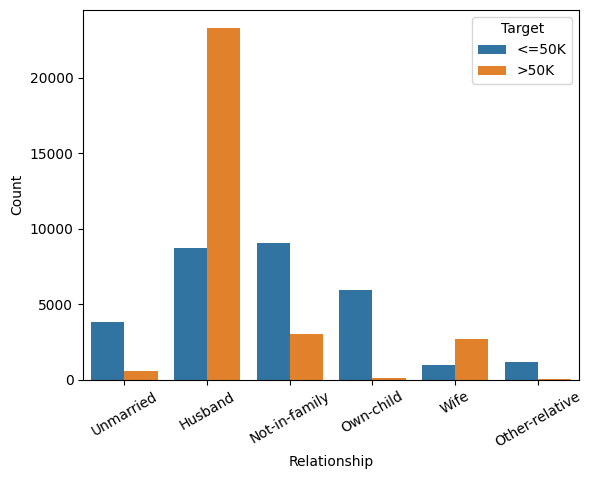

In [87]:
# Compare target with relationship
rel_cols = [
    "relationship_Husband",
    "relationship_Not-in-family",
    "relationship_Other-relative",
    "relationship_Own-child",
    "relationship_Unmarried",
    "relationship_Wife",
]
sns.countplot(
    x=X_train_bal[rel_cols].idxmax(axis=1).str.replace("relationship_", ""),
    hue=pd.Series(y_train_bal).map({1: ">50K", 0: "<=50K"}),
)
plt.xticks(rotation=30)
plt.xlabel("Relationship")
plt.ylabel("Count")
plt.legend(title="Target")
plt.show()

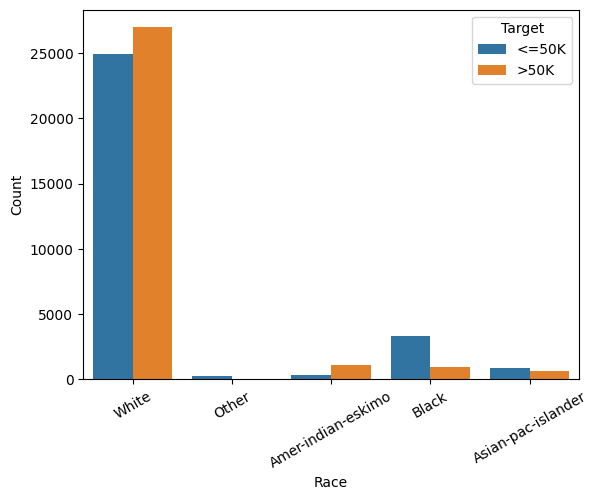

In [94]:
# Compare target with race
race_cols = [
    "race_Amer-indian-eskimo",
    "race_Asian-pac-islander",
    "race_Black",
    "race_Other",
    "race_White",
]
sns.countplot(
    x=X_train_bal[race_cols].idxmax(axis=1).str.replace("race_", ""),
    hue=pd.Series(y_train_bal).map({1: ">50K", 0: "<=50K"}),
)
plt.xticks(rotation=30)
plt.xlabel("Race")
plt.ylabel("Count")
plt.legend(title="Target")
plt.show()

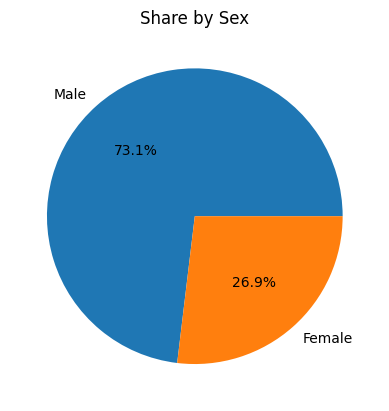

In [92]:
# Pie chart: sex share
sex_counts = X_train_bal[["sex_Female", "sex_Male"]].idxmax(axis=1).str.replace("sex_", "").value_counts()
plt.pie(sex_counts.values, labels=sex_counts.index, autopct="%1.1f%%")
plt.title("Share by Sex")
plt.show()

conclusion:
1. Male gender has earning salary more than female
2. Private job has more count than other jobs.
3. Married civ spouse has earning more.
4. Husband earning more
5. White race people earning more.